# 07 · Cost-model correlation: P1 vs pairwise speedups (seconds)

Recomputes the paper's claim:

> *An exploratory cost model based on workload characteristics has a Spearman rank correlation of 0.95
> with observed pairwise speedups across 17 datasets with completed comparisons.*

**No mining runs.** The notebook only reads two existing files. Every filter, exclusion and join is printed
so a reader can check each step. Cells assert the stated facts (17 pairs, three successful measurements
per timing, P1 matches the stored column), so the notebook fails loudly instead of quietly producing a
different number.

| Quantity | Definition |
|---|---|
| `P1` | `(F1 - 1) / (d_avg * (1 + d_cv**2))`, using exact `F1` at the support and raw transaction-width stats from `cost_stats.csv` (`P1_raw`) |
| `observed_ratio` | `median(classic wall s) / median(HybridFIM-1T wall s)` (`fastapriori_classic` / `fastapriori_fast_1t`) |
| Cell | k = 2, min_support = 0.0001, successful timings only |

**What the number is NOT:** it is rank association over 17 points, not 95% accuracy, explained variance, or
out-of-sample validation. The classic side ran with eight threads and HybridFIM-1T with one; section 7 repeats the correlation
with both at eight threads.

In [1]:
# ---- bundle configuration (same cell in every notebook) ----
import os, sys, json, time, hashlib
from pathlib import Path
import numpy as np
import pandas as pd

BUNDLE = Path.cwd().resolve().parent          # notebooks run from <bundle>/notebooks
assert (BUNDLE / "bench" / "baseline_runners.py").exists(), f"start Jupyter in <bundle>/notebooks (cwd={Path.cwd()})"
sys.path.insert(0, str(BUNDLE / "bench"))
DATA = Path(os.environ.get("FA_DATA_DIR", BUNDLE / "data"))
RESULTS = BUNDLE / "results"
DERIVED = RESULTS / "derived"                       # regenerated statistics, tables and figures

MAY = "campaign_2026-05"                           # the April/May 2026 GCE campaign
MAY_DIR = RESULTS / MAY
CAMPAIGN = os.environ.get("FA_CAMPAIGN", MAY) # set FA_CAMPAIGN=<id> to analyse a new run
CAMPAIGN_DIR = MAY_DIR if CAMPAIGN == MAY else RESULTS / "runs" / CAMPAIGN
AGG_CSV = (MAY_DIR / "results_rigorous_20260523_115442.csv" if CAMPAIGN == MAY
           else CAMPAIGN_DIR / f"results_rigorous_{CAMPAIGN}.csv")
LCM_CSV = MAY_DIR / "lcm_declat_results_20260523_055523.csv"
COST_CSV = (DERIVED / "cost_stats.csv") if (DERIVED / "cost_stats.csv").exists() else MAY_DIR / "cost_stats_20261022.csv"

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def rel(p):
    try:
        return Path(p).resolve().relative_to(BUNDLE).as_posix()
    except ValueError:
        return str(p)

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print(f"campaign : {CAMPAIGN}\nagg csv  : {rel(AGG_CSV)}")

campaign : campaign_2026-05
agg csv  : results/campaign_2026-05/results_rigorous_20260523_115442.csv


In [2]:
import matplotlib.pyplot as plt
from scipy import stats
RESULTS_CSV, COST = AGG_CSV, COST_CSV
FIG_DIR = DERIVED / "figures"
K, SUPPORT = 2, 0.0001
CLASSIC, FAST_1T = "fastapriori_classic", "fastapriori_fast_1t"

## 1 · Input provenance
File hashes and sizes pin exactly which snapshot produced the number below.

In [3]:
def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

for p in (RESULTS_CSV, COST):
    print(f"{rel(p)}\n  bytes={p.stat().st_size:,}  sha256={sha256(p)}")

res = pd.read_csv(RESULTS_CSV)
cost = pd.read_csv(COST)
print(f"\nresults rows={len(res):,}  datasets={res.dataset.nunique()}")
print(f"cost_stats rows={len(cost):,}  datasets={cost.dataset.nunique()}")
assert not res.duplicated(["dataset", "method", "k", "min_support"]).any(), "duplicate result cells"
assert not cost.duplicated(["dataset", "min_support"]).any(), "duplicate cost_stats rows"

results/campaign_2026-05/results_rigorous_20260523_115442.csv
  bytes=6,562,387  sha256=0f76d3232341a0b8d3670e752da58dc10efa9bbdd0c50f5972fdcf048720a03e
results/derived/cost_stats.csv
  bytes=16,475  sha256=5aa8c28db2814c67a07cd9c81a81007b93f055115a340d83c24414386e21fa9e



results rows=4,891  datasets=18
cost_stats rows=90  datasets=18


## 2 · Timing side: filter step by step
Each filter prints how many rows survive. "Successful" means every recorded measurement finished
(`wall_s_n_ok == wall_s_n_runs`, no timeout, no OOM).

In [4]:
step = res
print(f"{'all rows':<40}{len(step):>6}")
step = step[step.k == K];                         print(f"{'k == 2':<40}{len(step):>6}")
step = step[np.isclose(step.min_support, SUPPORT)]; print(f"{'min_support == 0.0001':<40}{len(step):>6}")
step = step[step.method.isin([CLASSIC, FAST_1T])]; print(f"{'method in {classic, fast_1t}':<40}{len(step):>6}")

timing_cols = ["dataset", "method", "wall_s_median", "wall_s_n_runs", "wall_s_n_ok",
               "wall_s_n_timeout", "wall_s_n_oom", "status_counts_json"]
timings = step[timing_cols].sort_values(["dataset", "method"]).reset_index(drop=True)
timings["successful"] = ((timings.wall_s_n_ok == timings.wall_s_n_runs)
                         & (timings.wall_s_n_timeout == 0) & (timings.wall_s_n_oom == 0)
                         & timings.wall_s_median.notna())
timings

all rows                                  4891
k == 2                                     777
min_support == 0.0001                      168
method in {classic, fast_1t}                35


,dataset,method,wall_s_median,wall_s_n_runs,wall_s_n_ok,wall_s_n_timeout,wall_s_n_oom,status_counts_json,successful
0,BMS-WebView-1,fastapriori_classic,0.091532,3,3,0,0,"{""ok"": 3}",True
1,BMS-WebView-1,fastapriori_fast_1t,0.026137,3,3,0,0,"{""ok"": 3}",True
2,BMS-WebView-2,fastapriori_classic,1.121933,3,3,0,0,"{""ok"": 3}",True
3,BMS-WebView-2,fastapriori_fast_1t,0.060014,3,3,0,0,"{""ok"": 3}",True
4,Chainstore,fastapriori_classic,68.315711,3,3,0,0,"{""ok"": 3}",True
5,Chainstore,fastapriori_fast_1t,1.887794,3,3,0,0,"{""ok"": 3}",True
6,Groceries,fastapriori_classic,0.029447,3,3,0,0,"{""ok"": 3}",True
7,Groceries,fastapriori_fast_1t,0.017950,3,3,0,0,"{""ok"": 3}",True
8,Instacart,fastapriori_classic,216.875621,3,3,0,0,"{""ok"": 3}",True
9,Instacart,fastapriori_fast_1t,9.084971,3,3,0,0,"{""ok"": 3}",True


### Which datasets are missing a timing, and why?

In [5]:
all_ds = sorted(res.dataset.unique())
present = timings[timings.successful].pivot(index="dataset", columns="method", values="wall_s_median")
present = present.reindex(all_ds)
missing = present[present.isna().any(axis=1)]
for ds, row in missing.iterrows():
    absent = [m for m in (CLASSIC, FAST_1T) if pd.isna(row.get(m))]
    for m in absent:
        rows_any = res[(res.dataset == ds) & (res.k == K) & (res.method == m)]
        print(f"{ds}: no successful {m} row at support={SUPPORT}.")
        print(f"  {m} rows for this dataset at k=2, any support:")
        print(rows_any[["min_support", "status_counts_json", "wall_s_n_ok"]].to_string(index=False))
        cov_path = (MAY_DIR / f"coverage_{CAMPAIGN}.csv") if CAMPAIGN == MAY else (DERIVED / f"coverage_{CAMPAIGN}.csv")
        cov = pd.read_csv(cov_path)
        att = cov[(cov.dataset == ds) & (cov.method == m) & (cov.k == K)]
        print(f"  attempted {m} cells at k=2 (warm-up probe status, from {rel(cov_path)}):")
        print(att[["min_support", "probe_status", "n_ok_timed"]].to_string(index=False))
if CAMPAIGN == MAY: assert list(missing.index) == ["T25.I8.D5000k.N40k.L40k"], missing.index.tolist()

T25.I8.D5000k.N40k.L40k: no successful fastapriori_classic row at support=0.0001.
  fastapriori_classic rows for this dataset at k=2, any support:
 min_support status_counts_json  wall_s_n_ok
       0.001          {"ok": 3}            3
       0.010          {"ok": 3}            3
  attempted fastapriori_classic cells at k=2 (warm-up probe status, from results/campaign_2026-05/coverage_campaign_2026-05.csv):
 min_support probe_status  n_ok_timed
      0.0001      timeout           0
      0.0005      timeout           0
      0.0010           ok           3
      0.0100           ok           3


`T25.I8.D5000k.N40k.L40k` has no successful classic timing at support 0.0001 because the classic
warm-up probe **timed out at the 1,500 s limit** (eight Rayon threads), as did 5e-4; only 1e-3 and 0.01
completed. The aggregated results table silently drops configurations whose probe failed, so the failure
is visible only in the coverage table built from the raw runs (`03_aggregate.ipynb`). The dataset is
excluded from the correlation as "no completed comparison"; the timeout implies classic/HybridFIM-1T
would be at least 1500/58.9 = 25 here.

In [6]:
ok = timings[timings.successful]
if CAMPAIGN == MAY: assert (ok.wall_s_n_ok == 3).all(), "three successful measurements per summary expected"
wide = ok.pivot(index="dataset", columns="method", values="wall_s_median").dropna()
wide["observed_ratio"] = wide[CLASSIC] / wide[FAST_1T]
print(f"datasets with both timings: {len(wide)}")
wide.sort_values("observed_ratio")

datasets with both timings: 17


method,fastapriori_classic,fastapriori_fast_1t,observed_ratio
dataset,,,
Groceries,0.029447,0.017950,1.640518
Online Retail,3.194612,1.293901,2.468978
T12.I4.D5k.N1k.L1k,0.166390,0.060525,2.749131
BMS-WebView-1,0.091532,0.026137,3.502034
T15.I8.D50k.N1k.L1k.high,0.699312,0.130168,5.372368
T15.I8.D50k.N1k.L1k.low,1.034809,0.185902,5.566426
T5.I2.D25k.N1k.L1k,0.162860,0.025318,6.432471
T30.I8.D50k.N5k.L5k,9.303795,0.686226,13.557916
Kosarak,32.879892,2.349520,13.994301


## 3 · Cost-model side: P1 from exact statistics
`P1` is recomputed from its components and checked against the stored `P1_raw` column. It uses the exact
`F1` (frequent single items at this support); it does **not** substitute `N`.

In [7]:
c = cost[np.isclose(cost.min_support, SUPPORT)].set_index("dataset")
print(f"cost_stats rows at support={SUPPORT}: {len(c)}")
c = c.assign(P1=(c.F1 - 1) / (c.d_avg * (1 + c.d_cv ** 2)))
max_abs_diff = (c.P1 - c.P1_raw).abs().max()
print(f"max |P1 recomputed - P1_raw| = {max_abs_diff:.3e}")
assert max_abs_diff < 1e-6
c[["D", "N", "F1", "d_avg", "d_cv", "P1", "P1_filtered"]].sort_values("P1")

cost_stats rows at support=0.0001: 18
max |P1 recomputed - P1_raw| = 2.274e-13


,D,N,F1,d_avg,d_cv,P1,P1_filtered
dataset,,,,,,,
Groceries,9835,169,169,4.409456,0.813978,22.916417,22.916417
BMS-WebView-1,59602,497,451,2.510637,1.932889,37.845244,37.869314
Online Retail,28816,4632,4062,17.772279,1.923310,48.626526,48.613370
T15.I8.D50k.N1k.L1k.high,50000,807,805,14.983880,0.257976,50.309479,50.309972
T15.I8.D50k.N1k.L1k.low,50000,1000,1000,15.006180,0.258167,62.412748,62.412748
T12.I4.D5k.N1k.L1k,5000,981,981,11.970400,0.285567,75.695735,75.695735
Kosarak,990002,41270,6494,8.099972,2.916603,84.321440,88.971957
T5.I2.D25k.N1k.L1k,24951,900,887,4.993387,0.445313,148.071539,148.089674
T30.I8.D50k.N5k.L5k,50000,4994,4992,30.042800,0.182404,160.780304,160.780896


### Cross-check: do both files describe the same datasets?
`D` and `N` should match the results file's `n_transactions` and `n_items`. The check also prints any `d_avg`
disagreement. P1 uses the `cost_stats` value.

In [8]:
meta = (res[(res.k == K) & np.isclose(res.min_support, SUPPORT)]
        .groupby("dataset")[["n_transactions", "n_items", "avg_items_per_txn"]].first())
chk = c[["D", "N", "d_avg"]].join(meta, how="outer")
chk["D_match"] = chk.D == chk.n_transactions
chk["N_match"] = chk.N == chk.n_items
chk["d_avg_rel_diff"] = (chk.d_avg - chk.avg_items_per_txn).abs() / chk.d_avg
print("D mismatches:", chk.index[~chk.D_match].tolist())
print("N mismatches:", chk.index[~chk.N_match].tolist())
print("d_avg disagreements > 0.1%:")
print(chk.loc[chk.d_avg_rel_diff > 1e-3, ["d_avg", "avg_items_per_txn", "d_avg_rel_diff"]].to_string())

D mismatches: []
N mismatches: []
d_avg disagreements > 0.1%:
                   d_avg  avg_items_per_txn  d_avg_rel_diff
dataset                                                    
Online Retail  17.772279          18.235043        0.026039


Only **Online Retail** disagrees (17.77 in `cost_stats` vs 18.24 in the results file, 2.6%). Cause:
`cost_stats` (notebook 04) drops duplicate (txn_id, item) rows before measuring widths, while the timing
harness (`load_datasets.load_online_retail`) keeps them; Online Retail has repeated items inside an
invoice. §5 reruns the correlation with the results-file statistics: the headline does not depend on it.

## 4 · Join and Spearman correlation

In [9]:
j = (c[["P1", "P1_filtered", "F1", "d_avg", "d_cv"]]
     .join(wide[["observed_ratio", CLASSIC, FAST_1T]], how="inner"))
print(f"complete pairs: {len(j)}")
if CAMPAIGN == MAY: assert len(j) == 17
assert not j.P1.duplicated().any() and not j.observed_ratio.duplicated().any(), "ties present"

j["rank_P1"] = j.P1.rank()
j["rank_ratio"] = j.observed_ratio.rank()
j["rank_diff"] = j.rank_P1 - j.rank_ratio
j.sort_values("rank_P1")

complete pairs: 17


,P1,P1_filtered,F1,d_avg,d_cv,observed_ratio,fastapriori_classic,fastapriori_fast_1t,rank_P1,rank_ratio,rank_diff
dataset,,,,,,,,,,,
Groceries,22.916417,22.916417,169,4.409456,0.813978,1.640518,0.029447,0.017950,1.0,1.0,0.0
BMS-WebView-1,37.845244,37.869314,451,2.510637,1.932889,3.502034,0.091532,0.026137,2.0,4.0,-2.0
Online Retail,48.626526,48.613370,4062,17.772279,1.923310,2.468978,3.194612,1.293901,3.0,2.0,1.0
T15.I8.D50k.N1k.L1k.high,50.309479,50.309972,805,14.983880,0.257976,5.372368,0.699312,0.130168,4.0,5.0,-1.0
T15.I8.D50k.N1k.L1k.low,62.412748,62.412748,1000,15.006180,0.258167,5.566426,1.034809,0.185902,5.0,6.0,-1.0
T12.I4.D5k.N1k.L1k,75.695735,75.695735,981,11.970400,0.285567,2.749131,0.166390,0.060525,6.0,3.0,3.0
Kosarak,84.321440,88.971957,6494,8.099972,2.916603,13.994301,32.879892,2.349520,7.0,9.0,-2.0
T5.I2.D25k.N1k.L1k,148.071539,148.089674,887,4.993387,0.445313,6.432471,0.162860,0.025318,8.0,7.0,1.0
T30.I8.D50k.N5k.L5k,160.780304,160.780896,4992,30.042800,0.182404,13.557916,9.303795,0.686226,9.0,8.0,1.0


In [10]:
rho, p = stats.spearmanr(j.P1, j.observed_ratio)

# The same number by hand: with no ties, rho = 1 - 6*sum(d^2) / (n(n^2-1)).
n = len(j)
rho_manual = 1 - 6 * (j.rank_diff ** 2).sum() / (n * (n ** 2 - 1))
assert np.isclose(rho, rho_manual)

print(f"n = {n}")
print(f"sum d^2 = {(j.rank_diff ** 2).sum():.0f}")
rho = float(rho)
print(f"Spearman rho = {rho!r}  (rounded: {rho:.2f})")
print(f"scipy two-sided p (asymptotic t, n=17): {p:.2e}")
if CAMPAIGN == MAY: assert abs(rho - 0.946078431372549) < 1e-12

n = 17
sum d^2 = 44
Spearman rho = 0.9460784313725492  (rounded: 0.95)
scipy two-sided p (asymptotic t, n=17): 9.65e-09


## 5 · Sensitivity: how fragile is 0.95?
These checks are descriptive and do not replace held-out validation:
* **leave-one-dataset-out**: the range of rho when each of the 17 datasets is dropped in turn;
* **P1_filtered**: transaction widths after removing infrequent items, instead of raw widths;
* **results-file d_avg**: substitutes `avg_items_per_txn` / `std_items_per_txn` from the timing file.

In [11]:
loo = pd.Series({ds: stats.spearmanr(j.drop(ds).P1, j.drop(ds).observed_ratio)[0] for ds in j.index},
                name="rho_without").sort_values()
print(f"leave-one-out rho: min={loo.min():.3f} ({loo.idxmin()})  max={loo.max():.3f} ({loo.idxmax()})")

rho_filt = stats.spearmanr(j.P1_filtered, j.observed_ratio)[0]

m = meta.reindex(j.index)
sd = res[(res.k == K) & np.isclose(res.min_support, SUPPORT)].groupby("dataset").std_items_per_txn.first()
d_alt = m.avg_items_per_txn
cv_alt = sd.reindex(j.index) / d_alt
P1_alt = (j.F1 - 1) / (d_alt * (1 + cv_alt ** 2))
rho_alt = stats.spearmanr(P1_alt, j.observed_ratio)[0]

sens = pd.DataFrame({"rho": [rho, rho_filt, rho_alt, loo.min(), loo.max()]},
                    index=["headline (P1_raw)", "P1_filtered", "results-file d_avg/d_cv",
                           "leave-one-out min", "leave-one-out max"])
sens.round(4)

leave-one-out rho: min=0.935 (Groceries)  max=0.956 (T12.I4.D5k.N1k.L1k)


,rho
headline (P1_raw),0.9461
P1_filtered,0.9461
results-file d_avg/d_cv,0.9461
leave-one-out min,0.9353
leave-one-out max,0.9559


## 6 · Correlation plot
Left: the measured values on log-log axes, labelled per dataset. Right: the ranks. Spearman rho is the
Pearson correlation of these ranks, so the right panel shows exactly what 0.95 measures. Filled circles are
real datasets; open squares are synthetic IBM-Quest datasets (`T…I…D…`).

saved ['results/derived/figures/p1_correlation_abstract.pdf', 'results/derived/figures/p1_correlation_abstract.png']


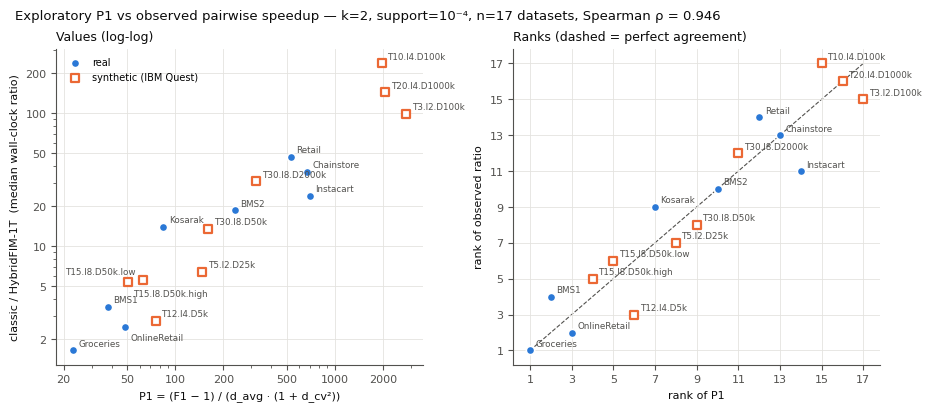

In [12]:
SHORT = {
    "BMS-WebView-1": "BMS1", "BMS-WebView-2": "BMS2", "Chainstore": "Chainstore",
    "Groceries": "Groceries", "Instacart": "Instacart", "Kosarak": "Kosarak",
    "Online Retail": "OnlineRetail", "Retail (Belgian)": "Retail",
}
def short(ds):
    if ds in SHORT:
        return SHORT[ds]
    parts = ds.split(".")                       # T15.I8.D50k.N1k.L1k.high -> T15.I8.D50k.high
    return ".".join(parts[:3] + parts[5:])

INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
REAL_C, SYN_C = "#2a78d6", "#eb6834"   # reference categorical slots 1 and 2
is_real = ~j.index.str.match(r"^T\d+\.I\d+")

plt.rcParams.update({"font.size": 8, "axes.edgecolor": INK2, "axes.labelcolor": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
                     "axes.spines.right": False})
fig, (a, b) = plt.subplots(1, 2, figsize=(9.2, 4.0), constrained_layout=True)

# Hand-placed offsets (points) for the values panel only, where these pairs collide.
OFFSETS = {"T15.I8.D50k.N1k.L1k.high": (4, -10), "T15.I8.D50k.N1k.L1k.low": (-5, 4, "right"),
           "Online Retail": (4, -10)}

def dots(ax, x, y, offsets={}):
    ax.scatter(x[is_real], y[is_real], s=36, c=REAL_C, edgecolors="white", linewidths=1.2,
               label="real", zorder=3)
    ax.scatter(x[~is_real], y[~is_real], s=36, marker="s", facecolors="white",
               edgecolors=SYN_C, linewidths=1.6, label="synthetic (IBM Quest)", zorder=3)
    for ds in j.index:
        dx, dy, *ha = offsets.get(ds, (4, 3))
        ax.annotate(short(ds), (x[ds], y[ds]), xytext=(dx, dy), textcoords="offset points",
                    fontsize=6.3, color=INK2, ha=ha[0] if ha else "left")
    ax.grid(True, color=GRID, linewidth=0.6, zorder=0)

dots(a, j.P1, j.observed_ratio, OFFSETS)
a.set_xscale("log"); a.set_yscale("log")
a.set_xticks([20, 50, 100, 200, 500, 1000, 2000]); a.set_yticks([2, 5, 10, 20, 50, 100, 200])
for axis in (a.xaxis, a.yaxis):
    axis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    axis.set_minor_formatter(plt.NullFormatter())
a.set_xlabel(r"P1 = (F1 − 1) / (d_avg · (1 + d_cv²))")
a.set_ylabel("classic / HybridFIM-1T  (median wall-clock ratio)")
a.set_title("Values (log-log)", color=INK, loc="left", fontsize=9)
a.legend(frameon=False, loc="upper left", fontsize=7)

dots(b, j.rank_P1, j.rank_ratio)
b.plot([1, n], [1, n], color=INK2, linewidth=0.8, linestyle="--", zorder=1)
b.set_xlabel("rank of P1"); b.set_ylabel("rank of observed ratio")
b.set_xticks(range(1, n + 1, 2)); b.set_yticks(range(1, n + 1, 2))
b.set_title("Ranks (dashed = perfect agreement)", color=INK, loc="left", fontsize=9)

fig.suptitle(f"Exploratory P1 vs observed pairwise speedup — k=2, support=10⁻⁴, "
             f"n={n} datasets, Spearman ρ = {rho:.3f}", color=INK, fontsize=9.5, x=0.01, ha="left")
FIG_DIR.mkdir(exist_ok=True)
for ext in ("pdf", "png"):
    fig.savefig(FIG_DIR / f"p1_correlation_abstract.{ext}", dpi=200)
print("saved", [rel(FIG_DIR / f"p1_correlation_abstract.{e}") for e in ("pdf", "png")])
plt.show()

## 7 · Matched threads: classic-8T vs HybridFIM-8T
The headline compares classic (Rayon default, eight threads on the 8-vCPU host) with HybridFIM pinned to
one thread. Here HybridFIM also runs with eight threads (`fastapriori_fast`), same filters, same 17 datasets.

In [13]:
FAST_8T = "fastapriori_fast"
t8 = res[(res.k == K) & np.isclose(res.min_support, SUPPORT) & res.method.isin([CLASSIC, FAST_8T])]
t8 = t8[(t8.wall_s_n_ok == t8.wall_s_n_runs) & (t8.wall_s_n_timeout == 0) & (t8.wall_s_n_oom == 0)
        & t8.wall_s_median.notna()]
w8 = t8.pivot(index="dataset", columns="method", values="wall_s_median")
j8 = c[["P1"]].join((w8[CLASSIC] / w8[FAST_8T]).rename("ratio_8t")).loc[j.index]
assert j8.ratio_8t.notna().all(), "a dataset of the headline lacks a matched 8T timing"
rho8 = float(stats.spearmanr(j8.P1, j8.ratio_8t)[0])
loo8 = pd.Series({ds: stats.spearmanr(j8.drop(ds).P1, j8.drop(ds).ratio_8t)[0] for ds in j8.index})
print(f"n = {len(j8)}; Spearman rho (classic-8T / HybridFIM-8T) = {rho8:.4f}")
print(f"leave-one-out: {loo8.min():.3f} .. {loo8.max():.3f}; speedups {j8.ratio_8t.min():.2f} .. {j8.ratio_8t.max():.1f}x")
if CAMPAIGN == MAY: assert len(j8) == 17 and abs(rho8 - 0.9240) < 5e-4

n = 17; Spearman rho (classic-8T / HybridFIM-8T) = 0.9240
leave-one-out: 0.909 .. 0.935; speedups 1.66 .. 412.8x
